# Lab 3: Comprehensive Data Analysis and Price Forecasting

By Alex Horyshevskyi

### Objective

Analyze, visualize, and forecast market price data using statistical analysis, regression models, and neural networks, while exploring data relationships, correlations, and model sensitivity.

In [278]:
%pip install numpy pandas matplotlib seaborn scikit-learn tabulate --quiet # type: ignore

Note: you may need to restart the kernel to use updated packages.


### Task 1: Enhanced Statistical Analysis

**Explanation**:<br>
We will perform enhanced statistical analysis on the filtered Global Food Prices Data. This involves calculating basic statistics (min, max, mean, quartiles, variance) for the `mp_price` field grouped by `cm_name`. We will also create a crosstab table for `cm_name` and `pt_name` and visualize the results using boxplots.

**Code**:<br>
We will use pandas for statistical analysis and matplotlib/seaborn for visualization.

In [279]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from os import path

Load the filtered datasets

- [Global Food Prices](https://data.humdata.org/dataset/global-wfp-food-prices)
- [Global Food Prices (Kaggle)](https://www.kaggle.com/datasets/salehahmedrony/global-food-prices)
- [Prices Dataset](https://fxtop.com/)
- [Alternative prices dataset (requires re-shaping)](https://data.imf.org/en/datasets/IMF.STA:ER)

In [ ]:
data_dir = "./data"

file_path = path.join(data_dir, "global_food_prices.csv")
global_food_prices_df = pd.read_csv(
    path.abspath(file_path), low_memory=False
)
filtered_global_food_prices_df = global_food_prices_df[
    global_food_prices_df["mp_year"] <= 2005
]

file_path = path.join(data_dir, "rates.csv")
rates_df = pd.read_csv(path.abspath(file_path), low_memory=False)

Calculate basic statistics for mp_price grouped by cm_name

In [282]:
stats = filtered_global_food_prices_df.groupby("cm_name")["mp_price"].describe()

Create a crosstab table for cm_name and pt_name

In [340]:
crosstab = pd.crosstab(
    filtered_global_food_prices_df["cm_name"], filtered_global_food_prices_df["pt_name"]
)

# Choose a cm_name for maximum variability of mp_price
n_opts = 5
top_n_options = (
    # Pick cm_name options with highest max - min mp_price
    (stats["max"] - stats["min"])
    .nlargest(n_opts)
    .index.tolist()
)
print(f"Top {n_opts} cm_name options with highest variability in mp_price:")
for option in top_n_options:
    print(f"- {option}")

filtered_global_food_prices_visualization_df = filtered_global_food_prices_df[
    filtered_global_food_prices_df["cm_name"].isin(top_n_options)
]

Top 5 cm_name options with highest variability in mp_price:
- Livestock (sheep, one-year-old alive female) - Retail
- Meat (camel) - Retail
- Livestock (Goat) - Retail
- Wage (non-qualified labour, non-agricultural) - Retail
- Fuel (diesel) - Retail


Visualize the results using boxplots

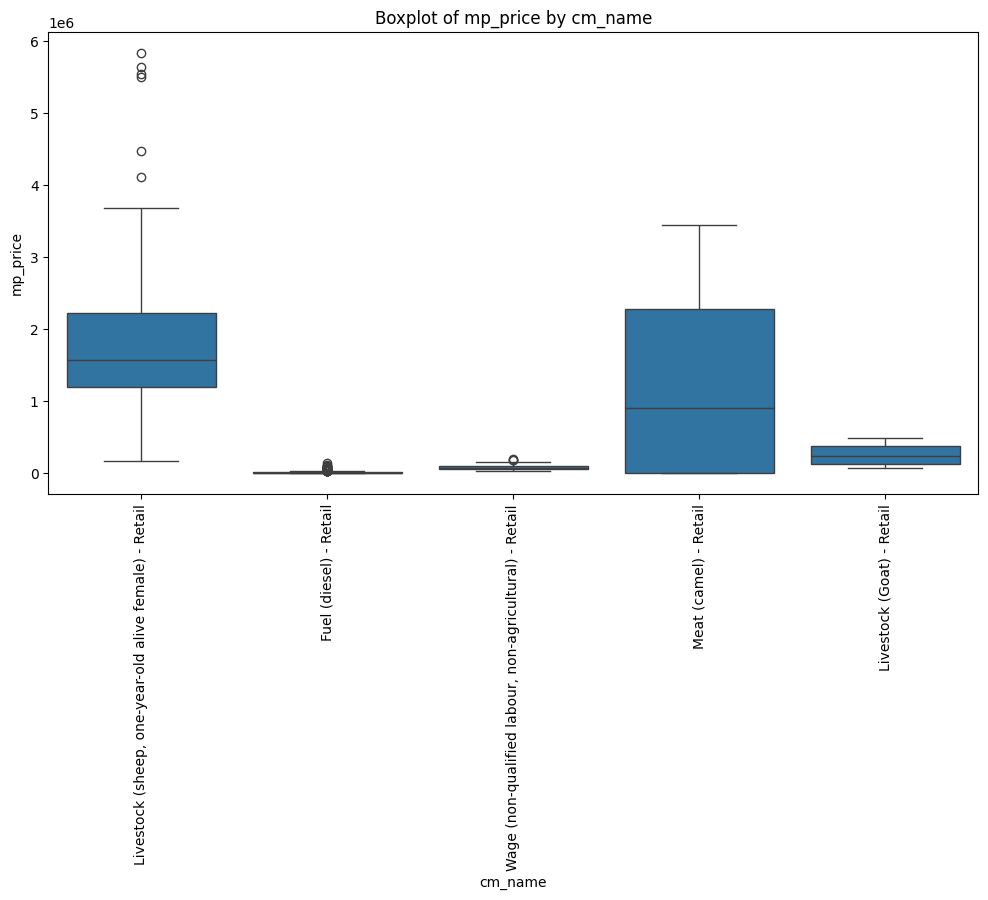

In [284]:
plt.figure(figsize=(12, 6))
sns.boxplot(x="cm_name", y="mp_price", data=filtered_global_food_prices_visualization_df)
plt.xticks(rotation=90)
plt.title("Boxplot of mp_price by cm_name")
plt.show()

In [285]:
print(f"""Basic Statistics for mp_price grouped by cm_name:
{stats.loc[top_n_options].to_markdown()}

Crosstab Table for cm_name and pt_name:
{crosstab.to_markdown()}""")

Basic Statistics for mp_price grouped by cm_name:
| cm_name                                                |   count |             mean |              std |      min |              25% |              50% |              75% |              max |
|:-------------------------------------------------------|--------:|-----------------:|-----------------:|---------:|-----------------:|-----------------:|-----------------:|-----------------:|
| Livestock (sheep, one-year-old alive female) - Retail  |     187 |      1.78676e+06 | 966727           | 168889   |      1.19525e+06 |      1.57667e+06 |      2.225e+06   |      5.83333e+06 |
| Meat (camel) - Retail                                  |      99 |      1.21492e+06 |      1.03164e+06 |     62.4 |    101.3         | 910000           |      2.28125e+06 |      3.45e+06    |
| Livestock (Goat) - Retail                              |      75 | 256474           | 131759           |  70667   | 127084           | 235000           | 385000           |

### Task 2: Visualization of Price Trends

**Explanation**:<br>
We will visualize the trends in `mp_price` over `mp_year` for a selected commodity. We will create a line plot for `mp_price` over `mp_year`, add a logarithmic column, and create scatter plots with different bin sizes.

**Code**:  
We will use matplotlib and seaborn for visualization.
Select a commodity (for example, the first commodity in the list)

In [286]:
rng = np.random.default_rng(seed=42)

selected_commodity = rng.choice(filtered_global_food_prices_df["cm_name"].unique())
commodity_data = filtered_global_food_prices_df[
    filtered_global_food_prices_df["cm_name"] == selected_commodity
]

Line plot for mp_price over mp_year

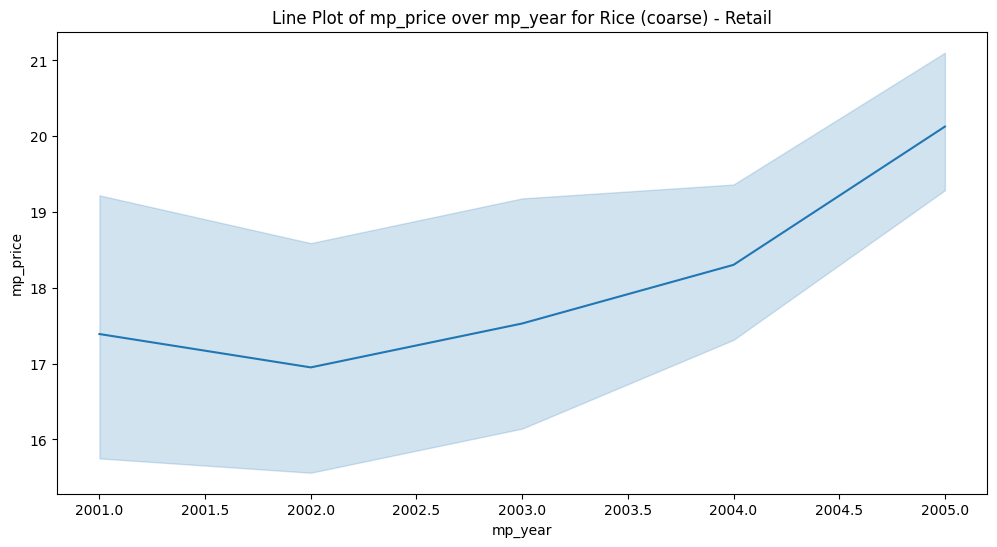

In [287]:
plt.figure(figsize=(12, 6))
sns.lineplot(x="mp_year", y="mp_price", data=commodity_data)
plt.title(f"Line Plot of mp_price over mp_year for {selected_commodity}")
plt.show()

Add a logarithmic column

In [288]:
commodity_data["log_mp_price"] = np.log(commodity_data["mp_price"])

/tmp/ipykernel_201222/2571397943.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  commodity_data["log_mp_price"] = np.log(commodity_data["mp_price"])


Scatter plot for mp_year vs log(mp_price)

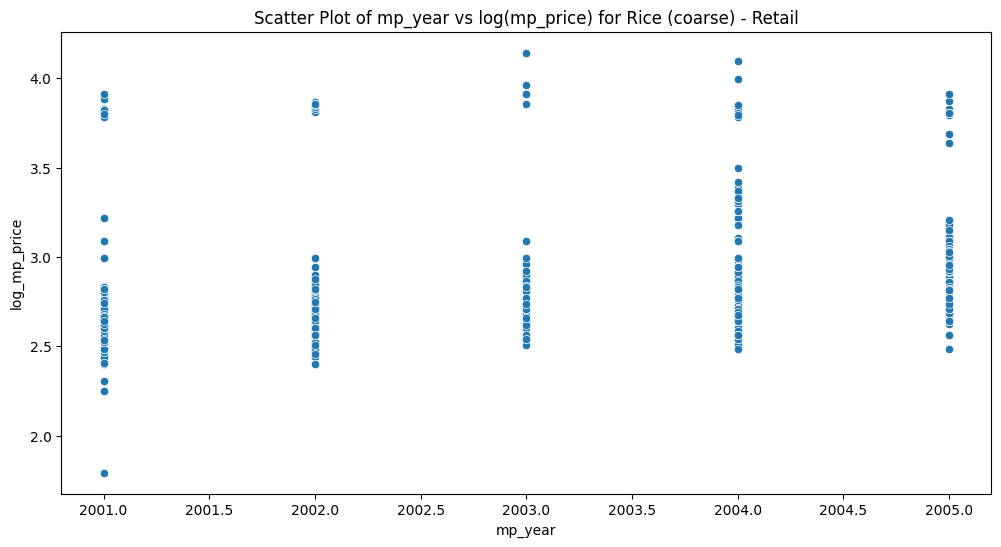

In [289]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x="mp_year", y="log_mp_price", data=commodity_data)
plt.title(f"Scatter Plot of mp_year vs log(mp_price) for {selected_commodity}")
plt.show()

Histograms with different bin sizes

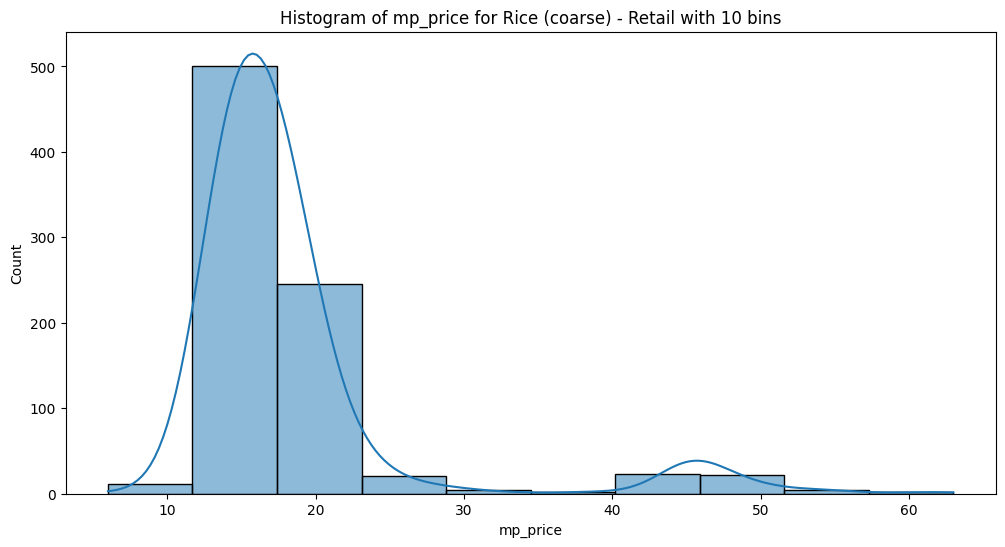

In [290]:
plt.figure(figsize=(12, 6))
sns.histplot(commodity_data["mp_price"], bins=10, kde=True)
plt.title(f"Histogram of mp_price for {selected_commodity} with 10 bins")
plt.show()

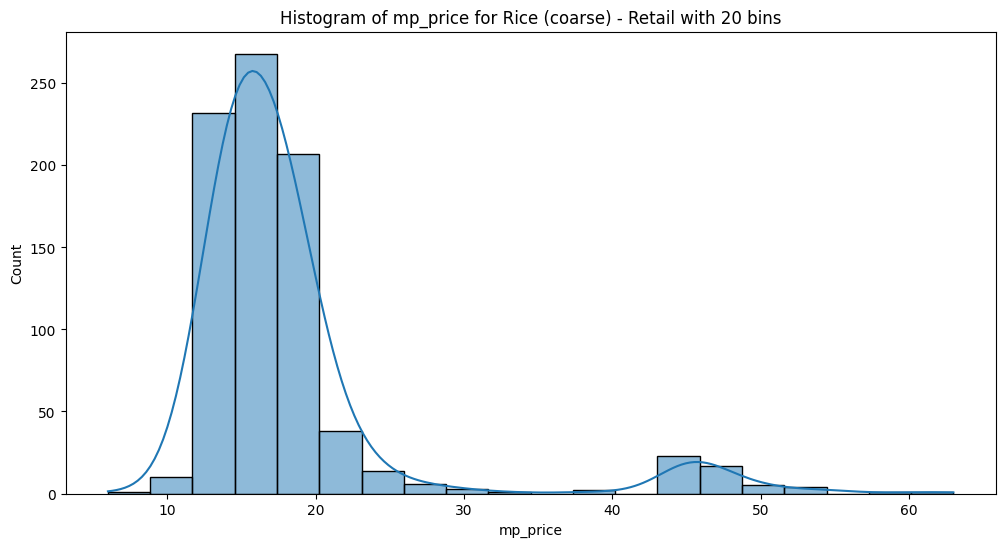

In [291]:
plt.figure(figsize=(12, 6))
sns.histplot(commodity_data["mp_price"], bins=20, kde=True)
plt.title(f"Histogram of mp_price for {selected_commodity} with 20 bins")
plt.show()

### Task 3: Handling Missing Data and Encoding Variables

**Explanation**:<br>
We will identify missing values in fields like `adm1_name` and `cm_name`, fill them with the mean or mode, and create a new column with encoded text variables.

**Code**:<br>
We will use pandas for handling missing data and encoding variables.

In [292]:
missing_values = filtered_global_food_prices_df.isnull().sum()
print(f"Missing Values:\n{missing_values.to_markdown()}")

Missing Values:
|                    |     0 |
|:-------------------|------:|
| adm0_id            |     0 |
| adm0_name          |     0 |
| adm1_id            |     0 |
| adm1_name          | 20042 |
| mkt_id             |     0 |
| mkt_name           |     0 |
| cm_id              |     0 |
| cm_name            |     0 |
| cur_id             |     0 |
| cur_name           |     0 |
| pt_id              |     0 |
| pt_name            |     0 |
| um_id              |     0 |
| um_name            |     0 |
| mp_month           |     0 |
| mp_year            |     0 |
| mp_price           |     0 |
| mp_commoditysource | 56861 |


Fill missing values with the mode for categorical variables

In [293]:
filtered_global_food_prices_df["adm1_name"].fillna(
    filtered_global_food_prices_df["adm1_name"].mode()[0], inplace=True
)
filtered_global_food_prices_df["cm_name"].fillna(
    filtered_global_food_prices_df["cm_name"].mode()[0], inplace=True
)

/tmp/ipykernel_201222/816235074.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_global_food_prices_df["adm1_name"].fillna(
/tmp/ipykernel_201222/816235074.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_global_food_prices_df["cm_name"].fillna(


Encode text variable (e.g., adm0_name)

In [294]:
from sklearn.preprocessing import LabelEncoder

In [295]:
le = LabelEncoder()
filtered_global_food_prices_df["adm0_name_encoded"] = le.fit_transform(
    filtered_global_food_prices_df["adm0_name"]
)

/tmp/ipykernel_201222/2488451237.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_global_food_prices_df["adm0_name_encoded"] = le.fit_transform(


Scatter plot for mp_year vs encoded variable

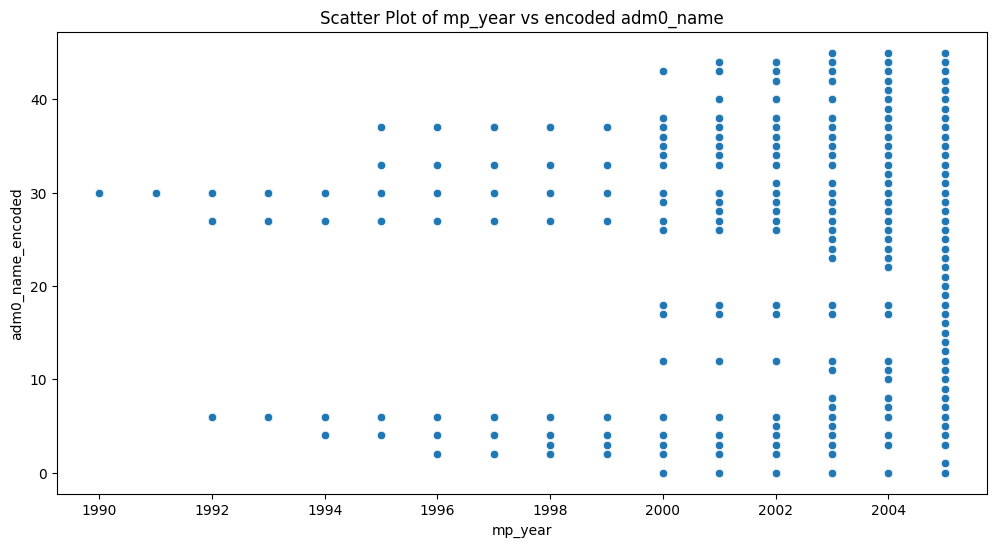

In [296]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x="mp_year", y="adm0_name_encoded", data=filtered_global_food_prices_df)
plt.title("Scatter Plot of mp_year vs encoded adm0_name")
plt.show()

### Task 4: Correlation Analysis Between Variables

**Explanation**:<br>
We will calculate the Pearson correlation between `mp_price` and other numerical fields (`mp_year`, `mp_month`), visualize the correlation matrix with a heatmap, and analyze strong correlations with scatter plots.

**Code**:<br>
We will use pandas and seaborn for correlation analysis and visualization.

In [297]:
correlation = filtered_global_food_prices_df[["mp_price", "mp_year", "mp_month"]].corr(
    method="pearson"
)
print(f"Pearson Correlation:\n{correlation.to_markdown()}")

Pearson Correlation:
|          |    mp_price |     mp_year |   mp_month |
|:---------|------------:|------------:|-----------:|
| mp_price |  1          | -0.00349291 | 0.00845636 |
| mp_year  | -0.00349291 |  1          | 0.00613961 |
| mp_month |  0.00845636 |  0.00613961 | 1          |


Visualize correlation matrix with a heatmap

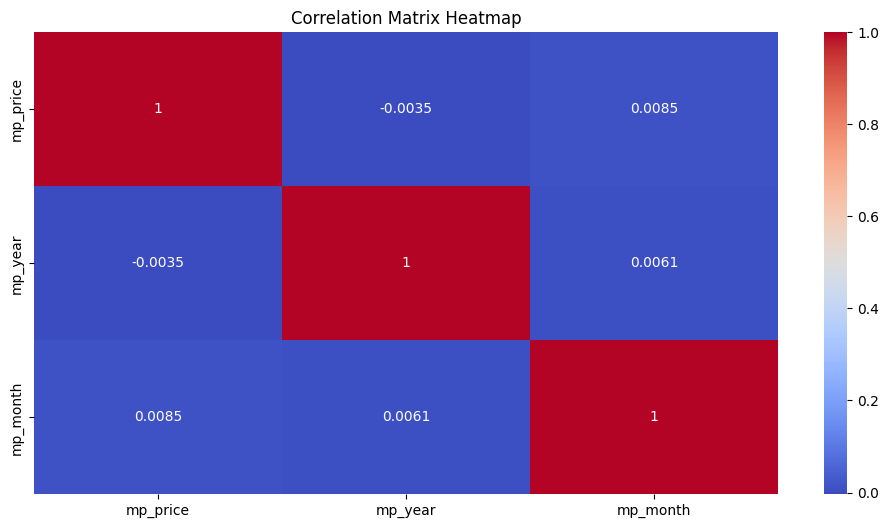

In [298]:
plt.figure(figsize=(12, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

Scatter plots for pairs with strong correlations

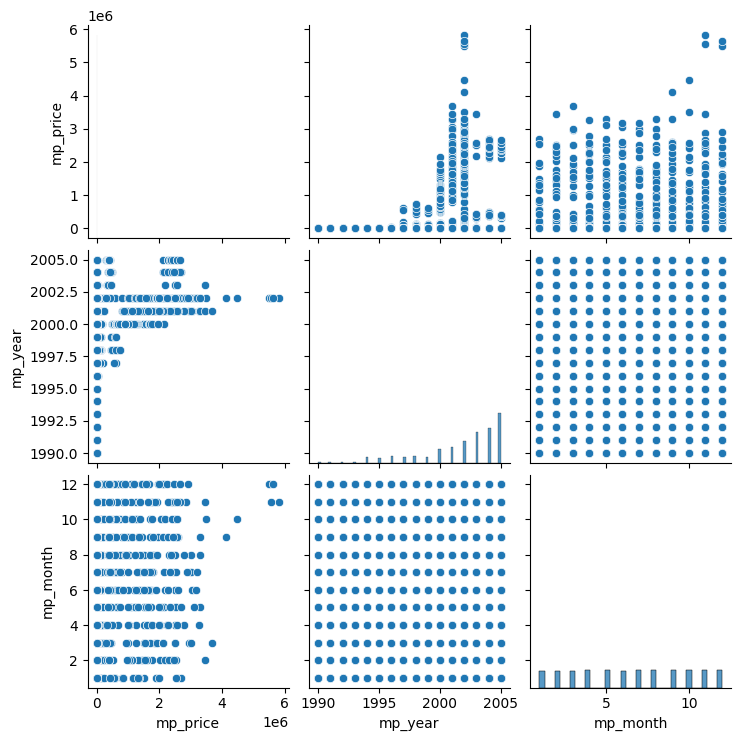

In [299]:
sns.pairplot(filtered_global_food_prices_df[["mp_price", "mp_year", "mp_month"]])
plt.show()

### Task 5: Price Prediction Using Linear Regression

**Explanation**:<br>
We will apply linear regression to predict `mp_price` based on `mp_year` for a selected commodity and calculate metrics like MAE, RMSE, R².

**Code**:<br>
We will use scikit-learn for linear regression and metrics calculation.

In [300]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Feature engineering for commodity data

In [301]:
commodity_data = filtered_global_food_prices_df[
    filtered_global_food_prices_df["cm_name"] == selected_commodity
].copy()

# Encode market names
commodity_data["mkt_name_encoded"] = le.fit_transform(
    commodity_data["mkt_name"]
)

# Reflect seasonality using sine and cosine transformations
commodity_data["month_sin"] = np.sin(2 * np.pi * commodity_data["mp_month"]/12)
commodity_data["month_cos"] = np.cos(2 * np.pi * commodity_data["mp_month"]/12)

# Create lag features
commodity_data["mp_price_prev_year"] = commodity_data["mp_price"].shift(1)
commodity_data["mp_price_prev_year"].bfill(inplace=True)

Select data

In [302]:
target_cols = [
        "mp_year",
        "mp_month",
        "mkt_name_encoded",
        "adm0_name_encoded",
        "month_sin",
        "month_cos",
        "mp_price_prev_year",
    ]

# X = commodity_data[["mp_year"]]
X = commodity_data[target_cols]

# Target variable logarithmically transformed for better modeling
y = np.log1p(commodity_data["mp_price"])

print(f"Shape of X: {X.shape}\nShape of y: {y.shape}")

Shape of X: (833, 7)
Shape of y: (833,)


Fit linear regression model

In [303]:
model = LinearRegression()
model.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Predictions

In [304]:
y_pred = model.predict(X)

Metrics

In [305]:
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print(f"""Model Performance Metrics:
- MAE: {mae}
- RMSE: {rmse}
- R^2: {r2}""")

Model Performance Metrics:
- MAE: 0.066634505056057
- RMSE: 0.11084259746329006
- R^2: 0.8607940812695183


Plot real data vs predictions

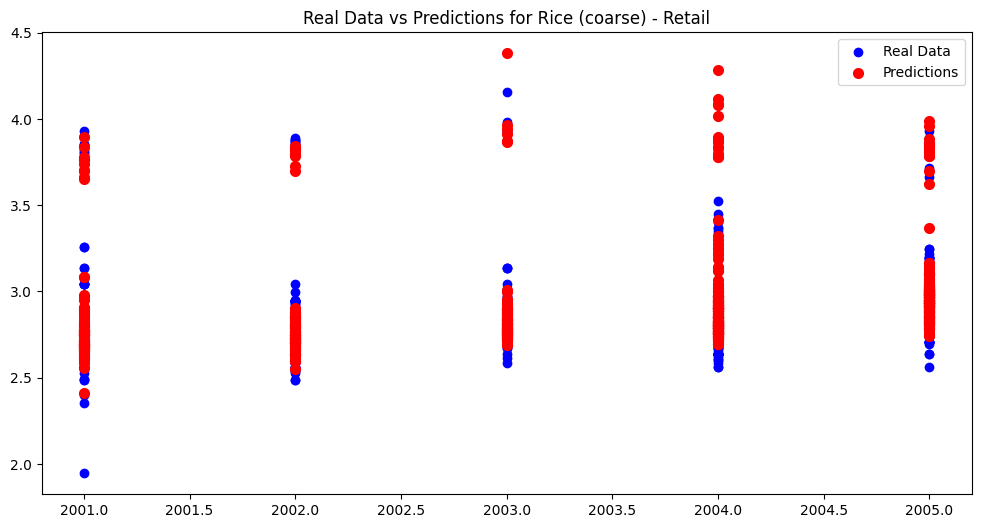

In [306]:
plt.figure(figsize=(12, 6))
plt.scatter(X["mp_year"], y, color="blue", label="Real Data")
plt.scatter(X["mp_year"], y_pred, color="red", linewidth=2, label="Predictions")
plt.title(f"Real Data vs Predictions for {selected_commodity}")
plt.legend()
plt.show()

### Task 6: Price Prediction Using Neural Network

**Explanation**:<br>
We will use MLPRegressor to predict `mp_price` based on `mp_year` and `mp_month`, compare accuracy with linear regression, and visualize predictions.

**Code**:<br>
We will use scikit-learn for MLPRegressor and metrics calculation.

In [307]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Select data

In [308]:
X_nn = commodity_data[target_cols]
y_nn = commodity_data["mp_price"]

print(f"Shape of X: {X_nn.shape}\nShape of y: {y_nn.shape}")

Shape of X: (833, 7)
Shape of y: (833,)


Fit MLPRegressor model

In [309]:
model_nn = MLPRegressor(hidden_layer_sizes=(100,), max_iter=1000)
model_nn.fit(X_nn, y_nn)

,loss,'squared_error'
,hidden_layer_sizes,"(100,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True


Predictions

In [310]:
y_pred_nn = model_nn.predict(X_nn)

Metrics

In [311]:
mae = mean_absolute_error(y_nn, y_pred_nn)
rmse = np.sqrt(mean_squared_error(y_nn, y_pred_nn))
r2 = r2_score(y_nn, y_pred_nn)

print(f"""Model Performance Metrics:
- MAE: {mae}
- RMSE: {rmse}
- R^2: {r2}""")

Model Performance Metrics:
- MAE: 1.2534394823376365
- RMSE: 2.6872213782173757
- R^2: 0.8895175185389699


Plot real data vs predictions

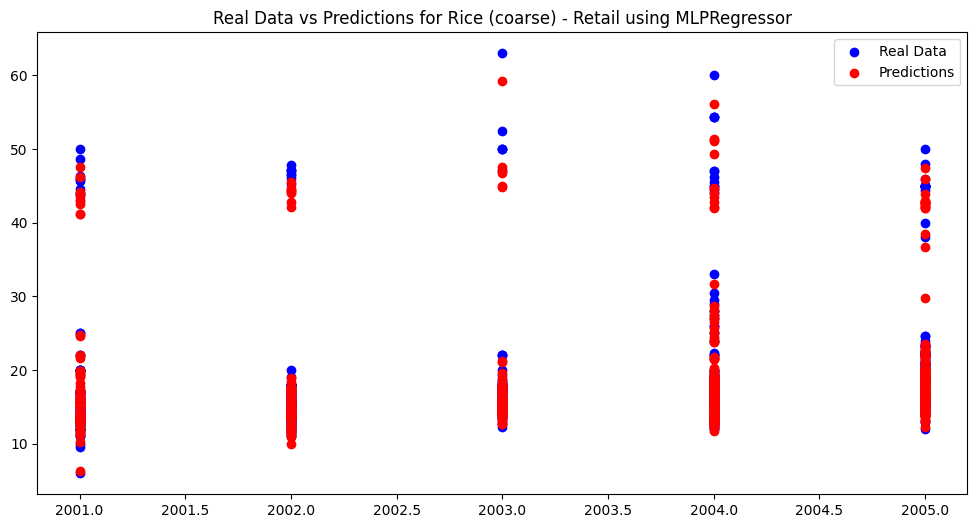

In [312]:
plt.figure(figsize=(12, 6))
plt.scatter(X_nn["mp_year"], y_nn, color="blue", label="Real Data")
plt.scatter(X_nn["mp_year"], y_pred_nn, color="red", label="Predictions")
plt.title(f"Real Data vs Predictions for {selected_commodity} using MLPRegressor")
plt.legend()
plt.show()

### Task 7: Market Relationship Analysis

**Explanation**:<br>
We will group data by `mkt_name` and `cm_name`, calculate average prices, and build a linear regression to predict prices in one market based on another.

**Code**:<br>
We will use pandas and scikit-learn for data grouping and linear regression.

In [313]:
grouped_data_year = (
    global_food_prices_df.groupby(["mkt_name", "mp_year"])["mp_price"]
    .mean()
    .reset_index()
)

Select two markets for comparison (for example, the two markets with the highest number of entries)

In [314]:
# Pick market names
market1, market2 = grouped_data_year["mkt_name"].value_counts().index[:2]

# Extract columns
market1_data_year = grouped_data_year[grouped_data_year["mkt_name"] == market1]
market2_data_year = grouped_data_year[grouped_data_year["mkt_name"] == market2]

Identify common years between both markets

In [315]:
common_years = set(market1_data_year['mp_year']).intersection(set(market2_data_year['mp_year']))

Filter the data to include only common years

In [316]:
market1_data_aligned = market1_data_year[market1_data_year['mp_year'].isin(common_years)]
market2_data_aligned = market2_data_year[market2_data_year['mp_year'].isin(common_years)]

Prepare data with aligned samples

In [317]:
X = market1_data_aligned["mp_price"].values.reshape(-1, 1)
y = market2_data_aligned["mp_price"].values.reshape(-1, 1)

print(f"Shape of X: {X.shape}\nShape of y: {y.shape}")

Shape of X: (32, 1)
Shape of y: (32, 1)


Fit linear regression model

In [318]:
model = LinearRegression()
model.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Predictions

In [319]:
y_pred = model.predict(X)

Plot real data vs predictions

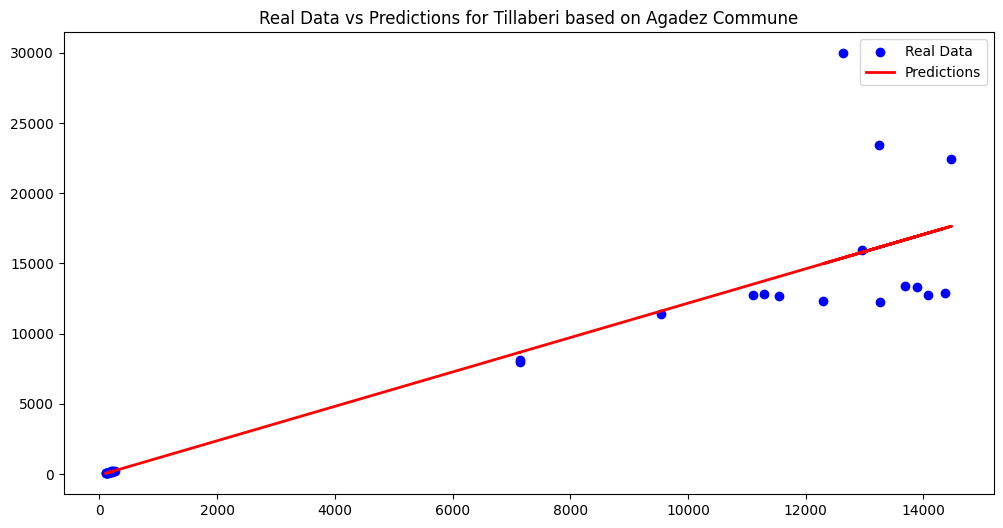

In [320]:
plt.figure(figsize=(12, 6))
plt.scatter(X, y, color="blue", label="Real Data")
plt.plot(X, y_pred, color="red", linewidth=2, label="Predictions")
plt.title(f"Real Data vs Predictions for {market2} based on {market1}")
plt.legend()
plt.show()

### Task 8: Analysis of the Impact of Exchange Rates

**Explanation**:<br>
We will convert `mp_price` to USD using exchange rate data and compare predictions with original data.

**Code**:<br>
We will use pandas for data manipulation and matplotlib for visualization.

In [321]:
target_currency = "GBP"

Filter data for specific currency and commodity  
For simplicity, we'll filter by commodity containing the keyword

In [322]:
# Use first word of selected commodity for filtering
commodity = selected_commodity.split()[0]
print(f"Filtering data for commodity containing keyword: {commodity}")

mask = filtered_global_food_prices_df["cm_name"].str.contains(
    commodity, case=False, na=False
)
commodity_df = filtered_global_food_prices_df[mask].copy()
print(
    f"Selected {commodity_df.shape[0]} records for commodities:\n{'\n'.join(commodity_df['cm_name'].unique().tolist())}"
)

if commodity_df.empty:
    raise ValueError(f"No data found for commodity: {commodity}")

Filtering data for commodity containing keyword: Rice
Selected 11450 records for commodities:
Rice (coarse) - Retail
Rice (coarse, BR-8/ 11/, Guti Sharna) - Wholesale
Rice - Retail
Rice - Wholesale
Rice (imported) - Wholesale
Rice (mixed, low quality) - Wholesale
Rice (imported) - Retail
Rice (local) - Retail
Rice (ordinary, first quality) - Wholesale
Rice (ordinary, second quality) - Wholesale
Rice (denikassia, imported) - Retail
Rice (basmati, broken) - Wholesale
Rice (Belem) - Wholesale
Rice (long grain) - Wholesale
Rice (ordinary, second quality) - Retail
Rice (tchako) - Retail
Rice (medium grain) - Retail
Rice (long grain, Sinaloa) - Wholesale
Rice (small grain, Morelos) - Wholesale
Rice (low quality) - Wholesale
Rice (basmati, broken) - Retail
Rice (regular, milled) - Wholesale
Rice (regular, milled) - Retail
Rice (milled, superior) - Wholesale
Rice (milled, superior) - Retail
Rice (red nadu) - Retail


Prepare exchange rate data

In [323]:
# Parse Month/Year column in rates_df
rates_df["Month"] = rates_df["Month/Year"].apply(
        lambda x: int(str(x).split("/")[0]) if "/" in str(x) else np.nan
    )
rates_df["Year"] = rates_df["Month/Year"].apply(
    lambda x: int(str(x).split("/")[1]) if "/" in str(x) else np.nan
)

# Merge with filtered data
commodity_df = commodity_df.merge(
    rates_df[["Month", "Year", target_currency]],
    left_on=["mp_month", "mp_year"],
    right_on=["Month", "Year"],
    how="left",
)

# Convert to USD (if exchange rate is available)
if target_currency in commodity_df.columns and not commodity_df[target_currency].isna().all():
    commodity_df["mp_price_usd"] = commodity_df["mp_price"] / commodity_df[target_currency]
else:
    print(f"Exchange rate data for {target_currency} not available, using original prices")
    commodity_df["mp_price_usd"] = commodity_df["mp_price"]

# Remove rows with NaN in USD prices
commodity_df = commodity_df.dropna(subset=["mp_price_usd"])

if len(commodity_df) < 10:
    raise ValueError(f"Insufficient data for analysis: {len(commodity_df)} rows")

# Encode market names
commodity_df["mkt_name_encoded"] = le.fit_transform(
    commodity_df["mkt_name"]
)

# Reflect seasonality using sine and cosine transformations
commodity_df["month_sin"] = np.sin(2 * np.pi * commodity_df["mp_month"]/12)
commodity_df["month_cos"] = np.cos(2 * np.pi * commodity_df["mp_month"]/12)

# Create lag features
commodity_df["mp_price_prev_year"] = commodity_df["mp_price"].shift(1)
commodity_df["mp_price_prev_year"].bfill(inplace=True)

Build regression model: mp_price_usd vs mp_year

In [324]:
X = commodity_df[target_cols]
y = commodity_df["mp_price_usd"]

model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

Calculate metrics

In [325]:
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print(f"""Model Performance Metrics (USD prices vs Year):
- MAE: {mae:.4f}
- RMSE: {rmse:.4f}
- R^2: {r2:.4f}
- Coefficient (slope): {model.coef_[0]:.4f}
- Intercept: {model.intercept_:.4f}""")

Model Performance Metrics (USD prices vs Year):
- MAE: 126.8364
- RMSE: 423.5919
- R^2: 0.9686
- Coefficient (slope): 17.5434
- Intercept: -35090.1643


Compare original and converted prices

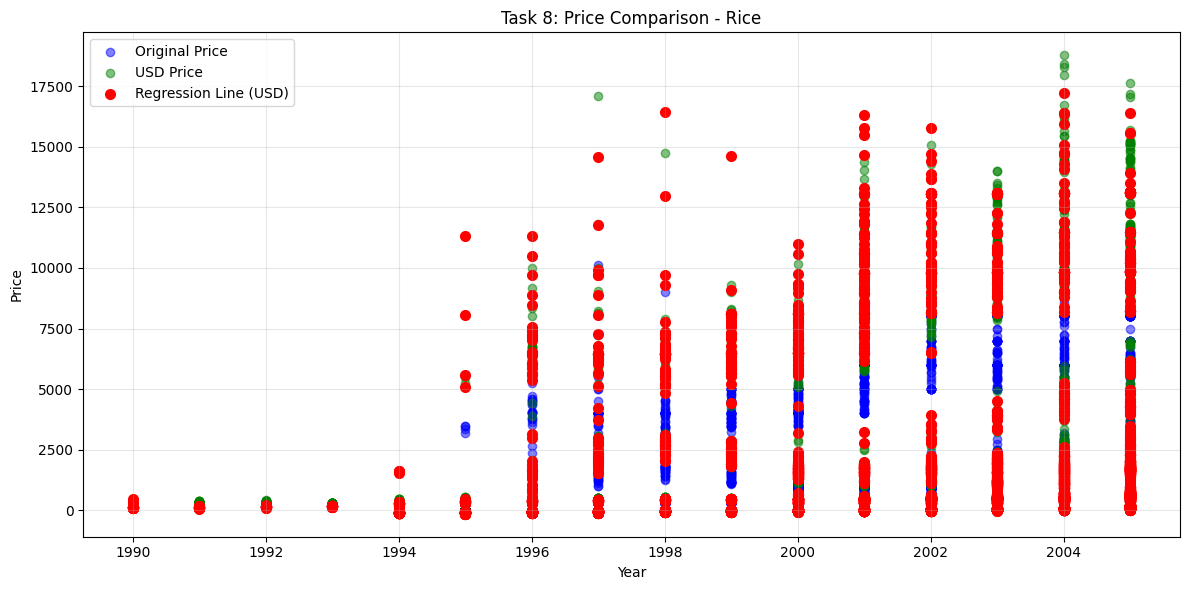

In [326]:
plt.figure(figsize=(12, 6))
plt.scatter(
    commodity_df["mp_year"],
    commodity_df["mp_price"],
    alpha=0.5,
    label="Original Price",
    color="blue",
)
plt.scatter(
    commodity_df["mp_year"],
    commodity_df["mp_price_usd"],
    alpha=0.5,
    label="USD Price",
    color="green",
)
plt.scatter(
    commodity_df["mp_year"],
    y_pred,
    color="red",
    linewidth=2,
    label="Regression Line (USD)",
)
plt.xlabel("Year")
plt.ylabel("Price")
plt.title(f"Task 8: Price Comparison - {commodity}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 9: Model Sensitivity Analysis

**Explanation**:<br>
We will apply a sensitivity function to evaluate the impact of changes in `mp_year` on `mp_price`.

**Code**:<br>
We will define a sensitivity function and apply it to the linear regression model.

Define sensitivity analysis function

In [327]:
def sensitivity_analysis(
    model, X, feature_index, changes, filter_index=None, filter_value=None, eps=1e-9
):
    """
    Single-feature sensitivity (additive, relative to feature range).
    - model: trained model with .predict
    - X: pandas DataFrame (features)
    - feature_index: int index (column position) or column name
    - changes: iterable of fractional changes e.g. [-0.2, -0.1, 0, 0.1, 0.2]
    - filter_index/filter_value: optional - apply filter BEFORE baseline & perturbation
    - eps: small value to avoid division by zero
    Returns: DataFrame with columns [feature, change, change_abs, mean_pred, delta, sensitivity_in_target]
    """
    # normalize feature_index to column name
    if isinstance(feature_index, int):
        feat_name = X.columns[feature_index]
    else:
        feat_name = feature_index

    # apply filter (same subset for baseline & perturbed)
    if (filter_index is not None) and (filter_value is not None):
        if isinstance(filter_index, int):
            filter_name = X.columns[filter_index]
        else:
            filter_name = filter_index
        mask = X[filter_name] == filter_value
        X_base = X.loc[mask].copy().reset_index(drop=True)
    else:
        X_base = X.copy().reset_index(drop=True)

    # compute base prediction & mean
    base_pred = model.predict(X_base)
    base_mean = np.mean(base_pred)
    if abs(base_mean) < eps:
        base_mean = eps  # avoid division by zero in sensitivity_in_target

    # feature range (on the base subset)
    feat_vals = X_base[feat_name].astype(float)
    feat_min, feat_max = feat_vals.min(), feat_vals.max()
    feat_range = feat_max - feat_min if feat_max != feat_min else eps

    rows = []
    for ch in changes:
        X_mod = X_base.copy().astype(float)
        X_mod[feat_name] = X_mod[feat_name] + (ch * feat_range)  # additive shift
        y_pred = model.predict(X_mod)
        mean_pred = np.mean(y_pred)
        delta = mean_pred - base_mean
        sensitivity_in_target = (delta / base_mean) * 100
        rows.append(
            {
                "scenario": f"{feat_name}_change_{ch:.2f}",
                "feature": feat_name,
                "change_frac": ch,
                "change_%": ch * 100,
                "change_abs": ch * feat_range,
                "mean_pred": mean_pred,
                "delta": delta,
                "sensitivity_in_target": sensitivity_in_target,
            }
        )
    return pd.DataFrame(rows)


def plot_sensitivity(results_df, title=None, figsize=(10, 5), text_labels=False):
    """
    Plot grouped sensitivity analysis results by scenario.
    Bars for each scenario are side-by-side for each change_% level.
    """
    plt.figure(figsize=figsize)

    # Ensure sorted and consistent ordering
    scenarios = list(results_df["scenario"].unique())
    changes = sorted(results_df["change_%"].unique())

    num_scenarios = len(scenarios)
    bar_width = 0.8 / num_scenarios  # total width of group = 0.8

    # x positions for the groups
    x_positions = np.arange(len(changes))

    for i, scenario in enumerate(scenarios):
        group = results_df[results_df["scenario"] == scenario].sort_values("change_%")

        # offset for each scenario
        offset = (i - num_scenarios / 2) * bar_width + bar_width / 2

        plt.bar(
            x_positions + offset,
            group["sensitivity_in_target"],
            width=bar_width,
            alpha=0.7,
            label=scenario,
        )

        if text_labels:
            for xi, yi in zip(x_positions + offset, group["sensitivity_in_target"]):
                plt.text(
                    xi,
                    yi + (0.03 * yi),
                    f"{yi}%",
                    ha="center",
                    va="bottom" if yi >= 0 else "top",
                    fontsize=8,
                )

    plt.axhline(0, color="k", linestyle="--", linewidth=0.6)
    plt.xticks(x_positions, [f"{c:+.0f}%" for c in changes])
    plt.xlabel("Change in input (%)")
    plt.ylabel("Change in predicted mp_price (%)")
    plt.title(title or "Extended Sensitivity Analysis (by Scenario)")
    plt.legend(title="Scenario")
    plt.grid(alpha=0.25, axis="y")
    plt.show()

Define changes (e.g., -20%, -10%, 0%, 10%, 20%)

In [328]:
change_levels = [-0.20, -0.10, -0.05, 0, 0.05, 0.10, 0.20]

Apply sensitivity analysis

In [329]:
print(f"Available features for sensitivity analysis: {X_nn.columns.tolist()}", end="\n\n")
analysis_target_feat_idx = X_nn.columns.get_loc("mp_year")

# filter_index, filter_value = None, None
filter_index, filter_value = (
    X_nn.columns.get_loc("mp_month"),
    6,
)  # Example: filter for June (mp_month=6)

sensitivities = sensitivity_analysis(
    model_nn, X_nn, analysis_target_feat_idx, change_levels, filter_index, filter_value,
)
print(sensitivities.to_markdown())

Available features for sensitivity analysis: ['mp_year', 'mp_month', 'mkt_name_encoded', 'adm0_name_encoded', 'month_sin', 'month_cos', 'mp_price_prev_year']

|    | scenario             | feature   |   change_frac |   change_% |   change_abs |   mean_pred |        delta |   sensitivity_in_target |
|---:|:---------------------|:----------|--------------:|-----------:|-------------:|------------:|-------------:|------------------------:|
|  0 | mp_year_change_-0.20 | mp_year   |         -0.2  |        -20 |         -0.8 |     18.5909 | -0.000566349 |            -0.00304629  |
|  1 | mp_year_change_-0.10 | mp_year   |         -0.1  |        -10 |         -0.4 |     18.5912 | -0.000283175 |            -0.00152314  |
|  2 | mp_year_change_-0.05 | mp_year   |         -0.05 |         -5 |         -0.2 |     18.5913 | -0.000141587 |            -0.000761572 |
|  3 | mp_year_change_0.00  | mp_year   |          0    |          0 |          0   |     18.5915 |  0           |             0        

Plot results

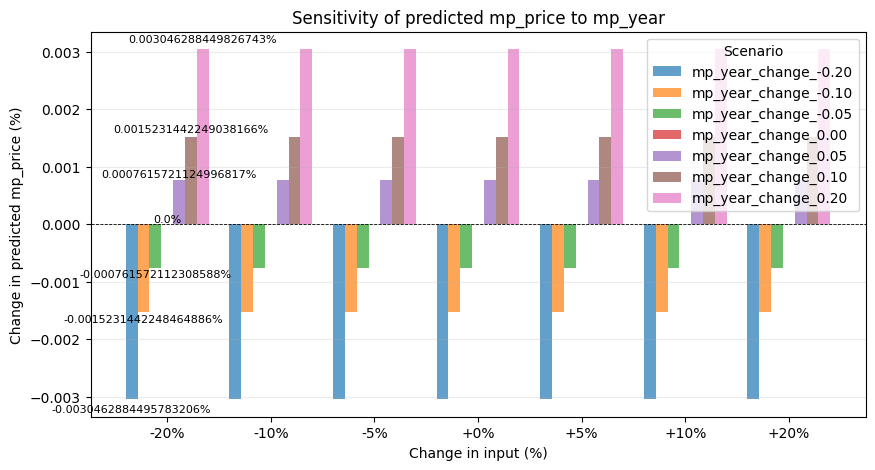

In [330]:
plot_sensitivity(sensitivities, title=f"Sensitivity of predicted mp_price to {sensitivities['feature'].iloc[0]}", text_labels=True)

### Task 10: Comparative Analysis of Commodity Groups

**Explanation**:<br>
We will group commodities into categories (e.g., grains, dairy), calculate statistics by group, and build regression to predict prices of one group based on another.

**Code**:  
We will use pandas for data grouping and scikit-learn for linear regression.
Group commodities into categories (this is a placeholder; actual grouping would depend on the data)

Define various commodity groups

In [331]:
# Define commodity groups
commodity_groups = {
    "Grains": ["Wheat", "Rice", "Maize", "Barley", "Bread"],
    "Vegetables": ["Tomatoes", "Onions", "Potatoes", "Carrots"],
    "Dairy": ["Milk", "Cheese", "Butter"],
    "Meat": ["Beef", "Chicken", "Pork", "Mutton"],
}

# Variant-specific group selection
variant_group_pairs = {
    1: ("Grains", "Vegetables"),
    2: ("Vegetables", "Dairy"),
    3: ("Grains", "Meat"),
    4: ("Dairy", "Meat"),
    5: ("Grains", "Dairy"),
}

# This is my variant number. You can change it to test other variants.
my_variant = 4
group1_name, group2_name = variant_group_pairs.get(my_variant, variant_group_pairs[1])
print(f"Variant {my_variant}: Comparing {group1_name} vs {group2_name}")

Variant 4: Comparing Dairy vs Meat


Engineer features for each group

In [332]:
# Assign groups to commodities
def assign_group(cm_name):
    for group, keywords in commodity_groups.items():
        for keyword in keywords:
            if keyword.lower() in str(cm_name).lower():
                return group
    return "Other"

filtered_global_food_prices_df["commodity_group"] = filtered_global_food_prices_df["cm_name"].apply(assign_group)

# Filter for selected groups
group_df = filtered_global_food_prices_df[
    filtered_global_food_prices_df["commodity_group"].isin([group1_name, group2_name])
].copy()

if group_df.empty:
    raise ValueError(f"No data found for groups: {group1_name}, {group2_name}")

/tmp/ipykernel_201222/624189441.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_global_food_prices_df["commodity_group"] = filtered_global_food_prices_df["cm_name"].apply(assign_group)


Calculate statistics by group

In [333]:
group_stats = group_df.groupby("commodity_group")["mp_price"].describe()
print(f"Statistics by Commodity Group:\n{group_stats.to_markdown()}")

Statistics by Commodity Group:
| commodity_group   |   count |     mean |      std |    min |    25% |       50% |    75% |      max |
|:------------------|--------:|---------:|---------:|-------:|-------:|----------:|-------:|---------:|
| Dairy             |     262 | 3075.05  | 3965.18  | 0.1587 | 0.7    | 2500      | 4143   | 30625    |
| Meat              |    1438 |  196.763 |  895.133 | 1.8333 | 6.0066 |    8.5002 |  105.5 |  6081.25 |


Build regression to predict prices of one group based on another

In [334]:
yearly_group = (
    group_df.groupby(["mp_year", "commodity_group"])["mp_price"]
    .mean()
    .unstack()
)

# Drop rows with NaN
yearly_group = yearly_group.dropna()

if len(yearly_group) < 5:
    raise ValueError(f"Insufficient data for regression: {len(yearly_group)} rows")

X_comp = yearly_group[[group1_name]]
y_comp = yearly_group[[group2_name]]

model = LinearRegression()
model.fit(X_comp, y_comp)
y_pred_comp = model.predict(X_comp)

# Calculate metrics
mae = mean_absolute_error(y_comp, y_pred_comp)
r2 = r2_score(y_comp, y_pred_comp)

print(f"""Regression Results ({group1_name} → {group2_name}):
- MAE: {mae:.4f}
- R²: {r2:.4f}
- Coefficient: {model.coef_[0][0]:.4f}
- Intercept: {model.intercept_[0]:.4f}""") # type: ignore

Regression Results (Dairy → Meat):
- MAE: 100.3920
- R²: 0.3324
- Coefficient: -0.0539
- Intercept: 345.1017


Plot results

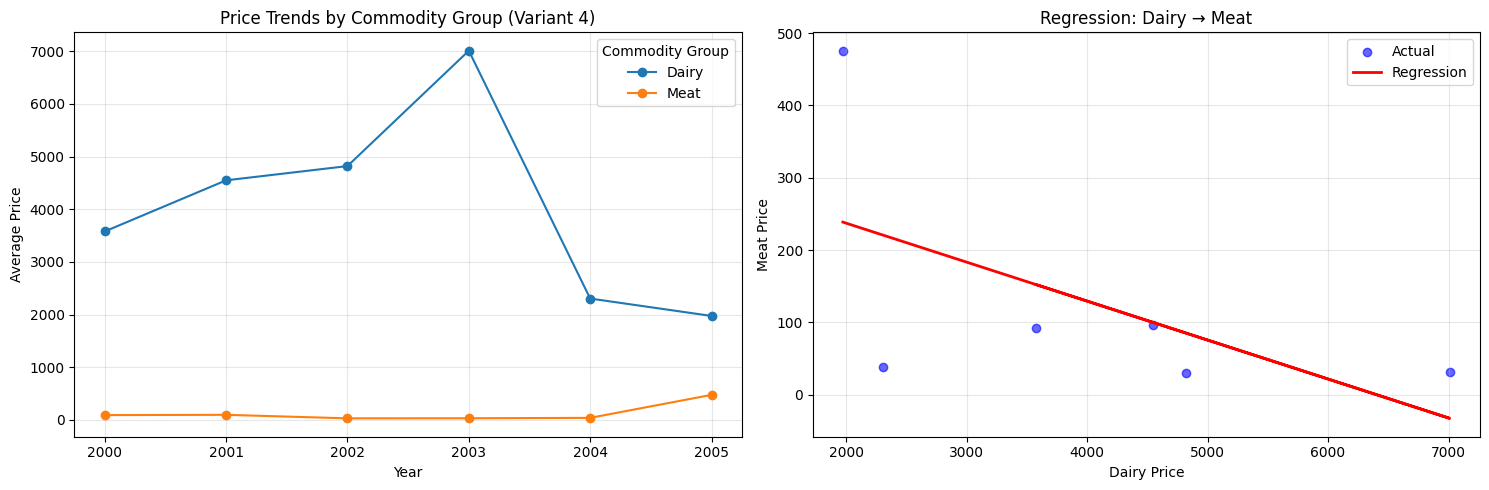

In [335]:
# Visualization 1: Group trends over time
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Trends over time
ax1 = axes[0]
yearly_group.plot(ax=ax1, marker="o")
ax1.set_xlabel("Year")
ax1.set_ylabel("Average Price")
ax1.set_title(f"Price Trends by Commodity Group (Variant {my_variant})")
ax1.legend(title="Commodity Group")
ax1.grid(True, alpha=0.3)

# Plot 2: Regression
ax2 = axes[1]
ax2.scatter(X_comp, y_comp, alpha=0.6, label="Actual", color="blue")
ax2.plot(X_comp, y_pred_comp, color="red", linewidth=2, label="Regression")
ax2.set_xlabel(f"{group1_name} Price")
ax2.set_ylabel(f"{group2_name} Price")
ax2.set_title(f"Regression: {group1_name} → {group2_name}")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Task 11: Extended Model Sensitivity Analysis

**Explanation**:<br>
We will select a regression or neural network model from previous tasks, calculate sensitivity for different levels of change in input variables, and visualize the results.

**Code**:<br>
We will define an extended sensitivity function and apply it to the selected model.

Define inputs for sensitivity analysis

In [336]:
feat_names = X_nn.columns.tolist()
feat_indices = [X_nn.columns.get_loc(name) for name in feat_names]

changes = [-0.20, -0.10, -0.05, 0, 0.05, 0.10, 0.20]

filter_index, filter_value = None, None
# Example: filter for June:
# filter_index, filter_value = X_data.columns.get_loc("mp_month"), 6

Define sensitivity analysis function

In [337]:
def extended_sensitivity_analysis(model, X, feature_list, changes, filter_index=None, filter_value=None, combined=True):
    """
    Run sensitivity_analysis for each feature in feature_list, plus optionally a combined scenario
    - feature_list: list of column names or indices
    - changes: list of fractional changes (same set applied to each feature individually)
    - combined: if True, apply the SAME change to ALL features simultaneously and record sensitivity
    Returns: concatenated DataFrame with results and a combined_df if combined=True
    """
    all_dfs = []
    for feat in feature_list:
        df_feat = sensitivity_analysis(model, X, feat, changes, filter_index, filter_value)
        df_feat["scenario"] = f"solo:{df_feat['feature'].iloc[0]}"
        all_dfs.append(df_feat)

    if not combined:
        result = pd.concat(all_dfs, ignore_index=True)
        return result, None

    # baseline subset
    if (filter_index is not None) and (filter_value is not None):
        if isinstance(filter_index, int):
            filter_name = X.columns[filter_index]
        else:
            filter_name = filter_index
        X_base = X[X[filter_name] == filter_value].copy().reset_index(drop=True)
    else:
        X_base = X.copy().reset_index(drop=True)

    base_pred = model.predict(X_base)
    base_mean = np.mean(base_pred)
    if abs(base_mean) < 1e-9:
        base_mean = 1e-9

    # compute ranges for each feature
    ranges = {}
    for feat in feature_list:
        fname = X.columns[feat] if isinstance(feat, int) else feat
        vals = X_base[fname].astype(float)
        r = vals.max() - vals.min()
        if r == 0:
            r = 1e-9
        ranges[fname] = r

    rows = []
    for ch in changes:
        X_mod = X_base.copy().astype(float)
        for feat in feature_list:
            fname = X.columns[feat] if isinstance(feat, int) else feat
            X_mod[fname] = X_mod[fname] + ch * ranges[fname]
        y_pred = model.predict(X_mod)
        mean_pred = np.mean(y_pred)
        delta = mean_pred - base_mean
        sensitivity_in_target = (delta / base_mean) * 100
        rows.append({
            "feature": "+".join([X.columns[f] if isinstance(f, int) else f for f in feature_list]),
            "change_frac": ch,
            "change_%": ch * 100,
            "change_abs": None,
            "mean_pred": mean_pred,
            "delta": delta,
            "sensitivity_in_target": sensitivity_in_target,
            "scenario": "combined",
        })

    combined_df = pd.DataFrame(rows)
    all_dfs.append(combined_df)
    result = pd.concat(all_dfs, ignore_index=True)
    return result, combined_df

Apply extended sensitivity analysis

In [338]:
results_df, combined_df = extended_sensitivity_analysis(
    model_nn, X_nn, feat_indices, changes,
    filter_index=filter_index, filter_value=filter_value, combined=True
)

/tmp/ipykernel_201222/1958886353.py:67: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result = pd.concat(all_dfs, ignore_index=True)


Plot results

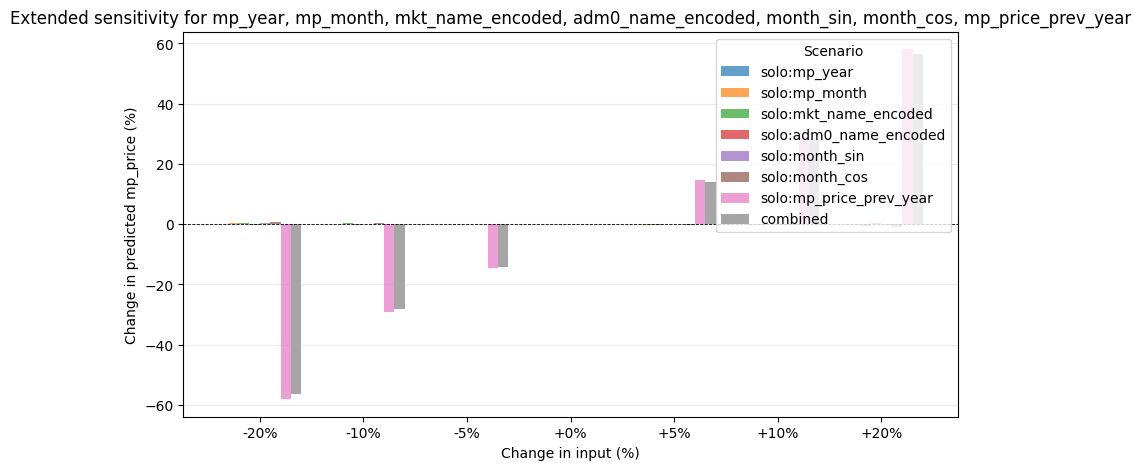

In [339]:
plot_sensitivity(results_df, title=f"Extended sensitivity for {', '.join(feat_names)}")

## Conclusion

The extended sensitivity analysis function provides insights into how changes in input features affect the target variable across different scenarios. By visualizing these sensitivities, we can better understand the robustness of our models and identify key drivers influencing market prices. This analysis is crucial for making informed decisions in dynamic market environments.

I gained valuable experience in implementing and interpreting sensitivity analyses, which will be beneficial for future projects.

I learned how to perform advanced data analysis, visualization, and forecasting using various statistical and machine learning techniques.

These skills will be valuable for future data science projects and real-world applications.  

Sensitivity analysis helped me understand model robustness and the impact of input changes on predictions. Finally, I gained experience in analyzing correlations, which are essential skills for any data analyst or scientist.  